In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("../dataset/Reviews.csv")

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully!
Rows: 568454
Columns: 10


In [2]:
df.head()

,Id,ProductId,UserId,ProfileName,HelpfulnessNumerator,HelpfulnessDenominator,Score,Time,Summary,Text
0,1,B001E4KFG0,A3SGXH7AUHU8GW,delmartian,1,1,5,1303862400,Good Quality Dog Food,I have bought several of the Vitality canned d...
1,2,B00813GRG4,A1D87F6ZCVE5NK,dll pa,0,0,1,1346976000,Not as Advertised,Product arrived labeled as Jumbo Salted Peanut...
2,3,B000LQOCH0,ABXLMWJIXXAIN,"Natalia Corres ""Natalia Corres""",1,1,4,1219017600,"""Delight"" says it all",This is a confection that has been around a fe...
3,4,B000UA0QIQ,A395BORC6FGVXV,Karl,3,3,2,1307923200,Cough Medicine,If you are looking for the secret ingredient i...
4,5,B006K2ZZ7K,A1UQRSCLF8GW1T,"Michael D. Bigham ""M. Wassir""",0,0,5,1350777600,Great taffy,Great taffy at a great price. There was a wid...


In [3]:
print("Column names:")
print(df.columns.tolist())

Column names:
['Id', 'ProductId', 'UserId', 'ProfileName', 'HelpfulnessNumerator', 'HelpfulnessDenominator', 'Score', 'Time', 'Summary', 'Text']


In [4]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
Id                         0
ProductId                  0
UserId                     0
ProfileName               26
HelpfulnessNumerator       0
HelpfulnessDenominator     0
Score                      0
Time                       0
Summary                   27
Text                       0
dtype: int64


## Step 3 — Dataset Inspection

The Amazon Product Reviews dataset contains approximately 568,455 customer
review records and 10 columns. The dataset contains product information,
customer information, review ratings, review summaries, and detailed review
text.

The `Score` column contains ratings from 1 to 5. The `Summary` and `Text`
columns contain customer-written reviews. The `Text` column will be used as
the primary text source for sentiment analysis.

In [5]:
print("Score distribution:")
print(df["Score"].value_counts().sort_index())

Score distribution:
Score
1     52268
2     29769
3     42640
4     80655
5    363122
Name: count, dtype: int64


In [6]:
def create_sentiment(score):
    if score <= 2:
        return "Negative"
    elif score == 3:
        return "Neutral"
    else:
        return "Positive"

df["Sentiment"] = df["Score"].apply(create_sentiment)

print("Sentiment labels created successfully!")

Sentiment labels created successfully!


In [7]:
print(df["Sentiment"].value_counts())

Sentiment
Positive    443777
Negative     82037
Neutral      42640
Name: count, dtype: int64


In [8]:
print(df[["Score", "Sentiment"]].head(10))

   Score Sentiment
0      5  Positive
1      1  Negative
2      4  Positive
3      2  Negative
4      5  Positive
5      4  Positive
6      5  Positive
7      5  Positive
8      5  Positive
9      5  Positive


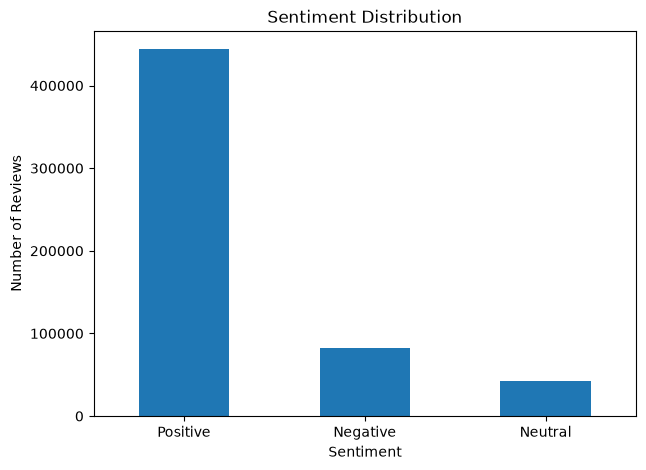

In [9]:
import matplotlib.pyplot as plt

sentiment_counts = df["Sentiment"].value_counts()

plt.figure(figsize=(7, 5))
sentiment_counts.plot(kind="bar")
plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.show()

### Observation — Sentiment Distribution

Customer reviews were categorized into Negative, Neutral, and Positive
sentiments based on their review scores. Ratings of 1–2 were classified as
Negative, a rating of 3 as Neutral, and ratings of 4–5 as Positive. The
distribution shows the overall sentiment pattern of customers toward the
reviewed products.

In [10]:
import re
import string

In [11]:
def clean_text(text):
    text = str(text)
    
    # Convert to lowercase
    text = text.lower()
    
    # Remove HTML tags
    text = re.sub(r"<.*?>", " ", text)
    
    # Remove URLs
    text = re.sub(r"http\S+|www\S+", " ", text)
    
    # Remove punctuation
    text = text.translate(str.maketrans("", "", string.punctuation))
    
    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()
    
    return text

In [12]:
df["Cleaned_Text"] = df["Text"].apply(clean_text)

print("Text cleaning completed!")

Text cleaning completed!


In [13]:
print("Original Review:")
print(df["Text"].iloc[0])

print("\nCleaned Review:")
print(df["Cleaned_Text"].iloc[0])

Original Review:
I have bought several of the Vitality canned dog food products and have found them all to be of good quality. The product looks more like a stew than a processed meat and it smells better. My Labrador is finicky and she appreciates this product better than  most.

Cleaned Review:
i have bought several of the vitality canned dog food products and have found them all to be of good quality the product looks more like a stew than a processed meat and it smells better my labrador is finicky and she appreciates this product better than most


In [14]:
empty_reviews = (df["Cleaned_Text"].str.len() == 0).sum()

print("Empty reviews after cleaning:", empty_reviews)

Empty reviews after cleaning: 0


### Observation — Text Cleaning

The customer review text was cleaned by converting it to lowercase, removing
HTML tags, URLs, punctuation, and unnecessary spaces. A cleaned text column
was created while preserving the original review text for reference. This
prepares the reviews for further text analysis and sentiment modeling.

In [15]:
from collections import Counter

In [16]:
all_words = " ".join(df["Cleaned_Text"]).split()

print("Total words:", len(all_words))

Total words: 45148087


In [17]:
word_counts = Counter(all_words)

print("Top 20 most common words:")
print(word_counts.most_common(20))

Top 20 most common words:
[('the', 1866644), ('i', 1495271), ('and', 1278851), ('a', 1199920), ('to', 1012659), ('it', 925334), ('of', 801092), ('is', 733421), ('this', 671420), ('for', 551312), ('in', 543798), ('my', 462345), ('that', 431693), ('but', 370442), ('with', 352484), ('have', 344952), ('not', 331913), ('you', 331325), ('are', 318728), ('was', 315237)]


In [18]:
stop_words = {
    "the", "and", "to", "of", "a", "in", "is", "for", "it",
    "this", "that", "was", "with", "on", "as", "i", "my",
    "but", "are", "have", "be", "we", "you", "they", "so",
    "not", "at", "or", "from", "had", "very", "an", "all",
    "were", "has", "would", "there", "what", "when", "just",
    "its", "can", "about", "one", "more", "will", "do"
}

filtered_words = [
    word for word in all_words
    if word not in stop_words and len(word) > 2
]

filtered_word_counts = Counter(filtered_words)

print("Top 20 meaningful words:")
print(filtered_word_counts.most_common(20))

Top 20 meaningful words:
[('like', 252677), ('these', 233491), ('them', 210345), ('good', 198221), ('taste', 169534), ('great', 165144), ('coffee', 163172), ('product', 149247), ('flavor', 145714), ('tea', 135600), ('love', 126887), ('food', 126412), ('out', 114721), ('than', 114282), ('get', 108417), ('other', 107266), ('some', 103377), ('really', 100790), ('only', 99741), ('dont', 95658)]


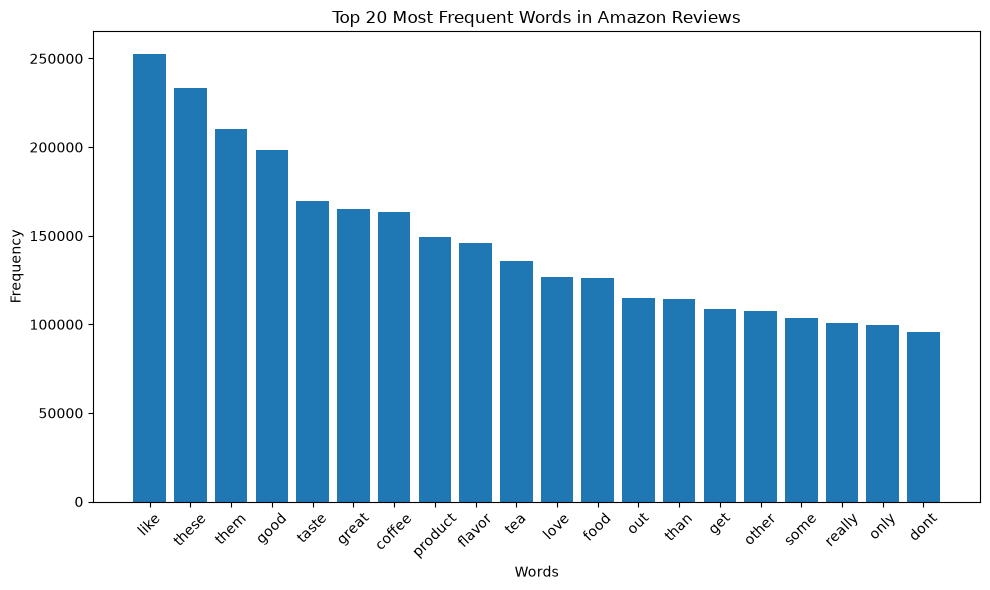

In [19]:
top_words = filtered_word_counts.most_common(20)

words = [item[0] for item in top_words]
counts = [item[1] for item in top_words]

plt.figure(figsize=(10, 6))
plt.bar(words, counts)
plt.title("Top 20 Most Frequent Words in Amazon Reviews")
plt.xlabel("Words")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Observation — Word Frequency

Word frequency analysis was performed on the cleaned customer reviews.
Common stop words were removed to focus on more meaningful terms. The most
frequent remaining words provide an overview of the topics and terms that
customers commonly mention in their product reviews.

In [20]:
positive_reviews = df[df["Sentiment"] == "Positive"]["Cleaned_Text"]
negative_reviews = df[df["Sentiment"] == "Negative"]["Cleaned_Text"]

print("Positive reviews:", len(positive_reviews))
print("Negative reviews:", len(negative_reviews))

Positive reviews: 443777
Negative reviews: 82037


In [21]:
positive_words = " ".join(positive_reviews).split()

positive_words = [
    word for word in positive_words
    if word not in stop_words and len(word) > 2
]

positive_counts = Counter(positive_words)

print("Top 20 words in Positive Reviews:")
print(positive_counts.most_common(20))

Top 20 words in Positive Reviews:
[('these', 185248), ('like', 182766), ('them', 167506), ('good', 158341), ('great', 148903), ('coffee', 123171), ('taste', 118730), ('love', 111820), ('flavor', 109186), ('tea', 109135), ('product', 102823), ('food', 95344), ('than', 88828), ('out', 83006), ('get', 82396), ('other', 81184), ('some', 79144), ('only', 76482), ('really', 76422), ('too', 71652)]


In [22]:
negative_words = " ".join(negative_reviews).split()

negative_words = [
    word for word in negative_words
    if word not in stop_words and len(word) > 2
]

negative_counts = Counter(negative_words)

print("Top 20 words in Negative Reviews:")
print(negative_counts.most_common(20))

Top 20 words in Negative Reviews:
[('like', 43822), ('product', 32200), ('taste', 31445), ('these', 31013), ('them', 27687), ('food', 22417), ('coffee', 22191), ('out', 21503), ('good', 21388), ('flavor', 20095), ('dont', 17531), ('even', 16341), ('other', 16320), ('get', 16061), ('tea', 16053), ('because', 16038), ('only', 15067), ('buy', 14967), ('some', 14709), ('really', 14431)]


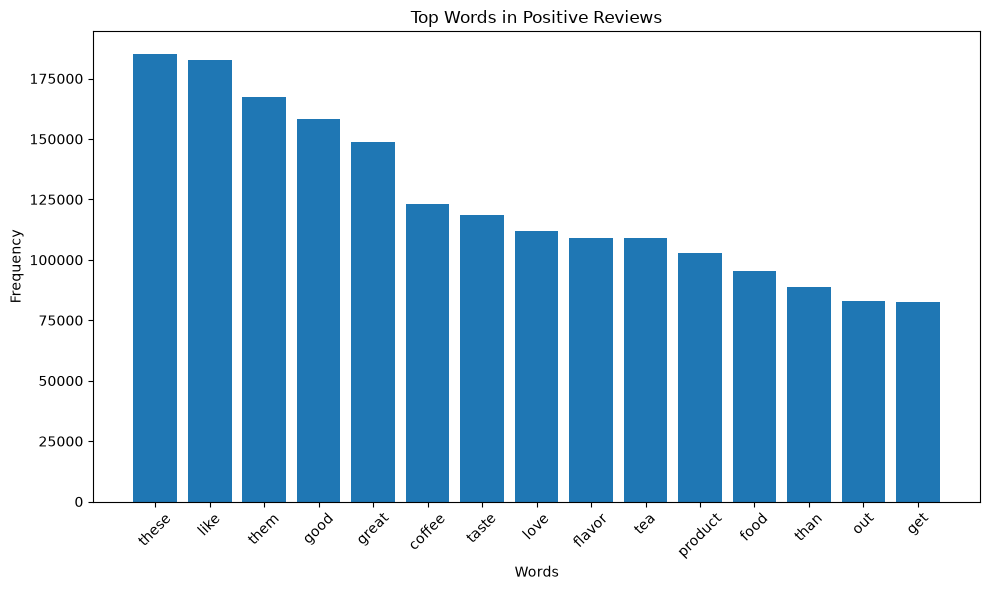

In [23]:
top_positive = positive_counts.most_common(15)

words = [item[0] for item in top_positive]
counts = [item[1] for item in top_positive]

plt.figure(figsize=(10, 6))
plt.bar(words, counts)
plt.title("Top Words in Positive Reviews")
plt.xlabel("Words")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

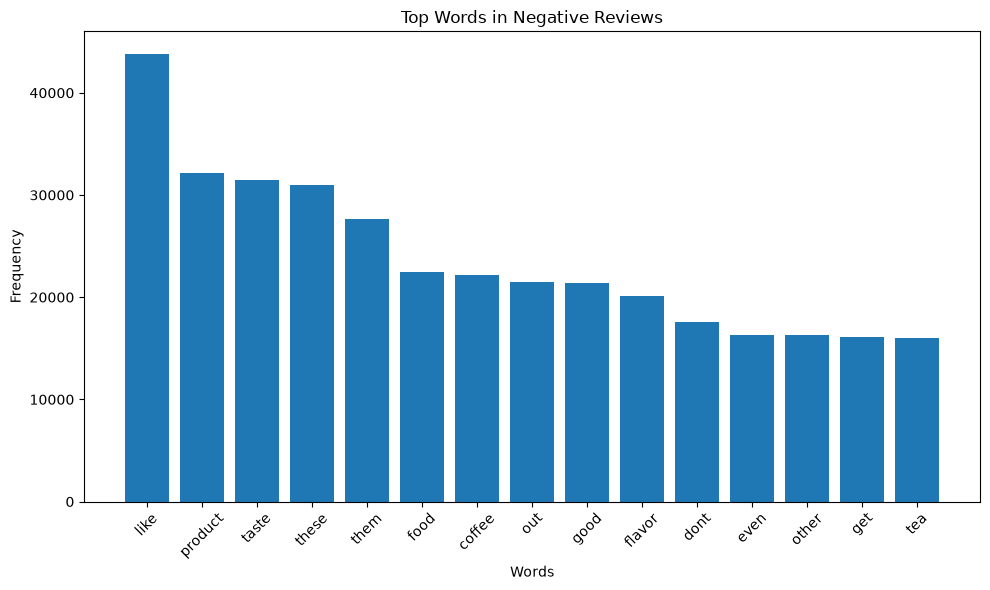

In [24]:
top_negative = negative_counts.most_common(15)

words = [item[0] for item in top_negative]
counts = [item[1] for item in top_negative]

plt.figure(figsize=(10, 6))
plt.bar(words, counts)
plt.title("Top Words in Negative Reviews")
plt.xlabel("Words")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Observation — Positive and Negative Review Analysis

The most frequent words in positive and negative reviews were analyzed
separately. Positive reviews commonly contain words associated with
satisfaction, quality, recommendation, and product experience, while negative
reviews can reveal common complaints and areas of dissatisfaction. These
patterns can help identify customer preferences and potential product or
service improvement areas.

In [25]:
sample_size = 20000

positive_sample = df[df["Sentiment"] == "Positive"].sample(
    n=min(sample_size, len(df[df["Sentiment"] == "Positive"])),
    random_state=42
)

negative_sample = df[df["Sentiment"] == "Negative"].sample(
    n=min(sample_size, len(df[df["Sentiment"] == "Negative"])),
    random_state=42
)

neutral_sample = df[df["Sentiment"] == "Neutral"].sample(
    n=min(sample_size, len(df[df["Sentiment"] == "Neutral"])),
    random_state=42
)

model_df = pd.concat([
    positive_sample,
    negative_sample,
    neutral_sample
]).sample(frac=1, random_state=42).reset_index(drop=True)

print("Model dataset shape:", model_df.shape)
print("\nSentiment distribution:")
print(model_df["Sentiment"].value_counts())

Model dataset shape: (60000, 12)

Sentiment distribution:
Sentiment
Positive    20000
Negative    20000
Neutral     20000
Name: count, dtype: int64


In [26]:
from sklearn.model_selection import train_test_split

X = model_df["Cleaned_Text"]
y = model_df["Sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training reviews:", len(X_train))
print("Testing reviews:", len(X_test))

Training reviews: 48000
Testing reviews: 12000


In [27]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=10000,
    min_df=2,
    max_df=0.95
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (48000, 10000)
Testing TF-IDF shape: (12000, 10000)


## Step 8 — TF-IDF Feature Preparation

A balanced sample of the Amazon review dataset was prepared for machine
learning to reduce computational requirements while maintaining
representation from each sentiment class.

The cleaned review text was converted into numerical features using
Term Frequency–Inverse Document Frequency (TF-IDF). The dataset was then
divided into training and testing sets using stratified sampling so that the
sentiment distribution remained consistent.

In [28]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model.fit(X_train_tfidf, y_train)

print("Sentiment model trained successfully!")

Sentiment model trained successfully!


In [29]:
y_pred = model.predict(X_test_tfidf)

print("Predictions completed!")
print("Number of predictions:", len(y_pred))

Predictions completed!
Number of predictions: 12000


In [30]:
results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

print(results.head(20))

      Actual Predicted
0    Neutral  Positive
1   Negative  Negative
2   Positive  Positive
3   Positive  Positive
4   Positive  Positive
5   Negative  Negative
6   Positive  Positive
7   Positive  Positive
8   Negative  Negative
9   Negative  Negative
10  Negative  Negative
11  Negative   Neutral
12  Negative  Negative
13   Neutral   Neutral
14  Positive  Positive
15  Negative   Neutral
16  Positive  Negative
17  Positive  Positive
18   Neutral   Neutral
19  Positive   Neutral


## Step 9 — Sentiment Classification Model

A Logistic Regression classification model was trained using the TF-IDF
features generated from customer review text. The model was used to predict
the sentiment of reviews in the test dataset as Positive, Neutral, or
Negative.

In [31]:
from sklearn.metrics import accuracy_score, classification_report

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Model Accuracy: 72.72 %

Classification Report:
              precision    recall  f1-score   support

    Negative       0.73      0.73      0.73      4000
     Neutral       0.65      0.65      0.65      4000
    Positive       0.80      0.80      0.80      4000

    accuracy                           0.73     12000
   macro avg       0.73      0.73      0.73     12000
weighted avg       0.73      0.73      0.73     12000



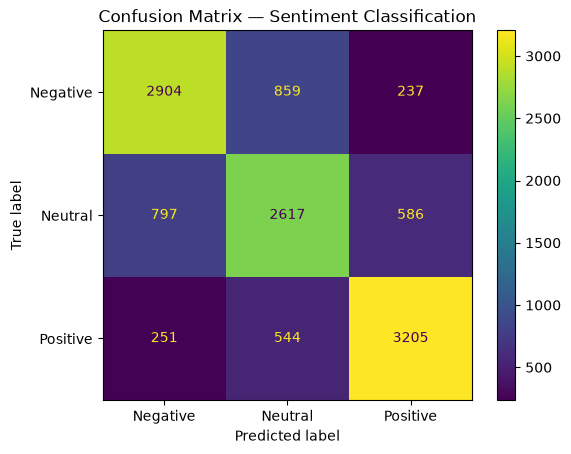

In [32]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["Negative", "Neutral", "Positive"]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Neutral", "Positive"]
)

disp.plot()
plt.title("Confusion Matrix — Sentiment Classification")
plt.show()

### Observation — Model Evaluation

The Logistic Regression model was evaluated using accuracy, precision, recall,
and F1-score. The confusion matrix was also used to examine how correctly the
model classified Negative, Neutral, and Positive reviews.

The evaluation results indicate the overall effectiveness of the TF-IDF based
sentiment classification model. The actual performance metrics obtained from
the test dataset should be used when interpreting the model.

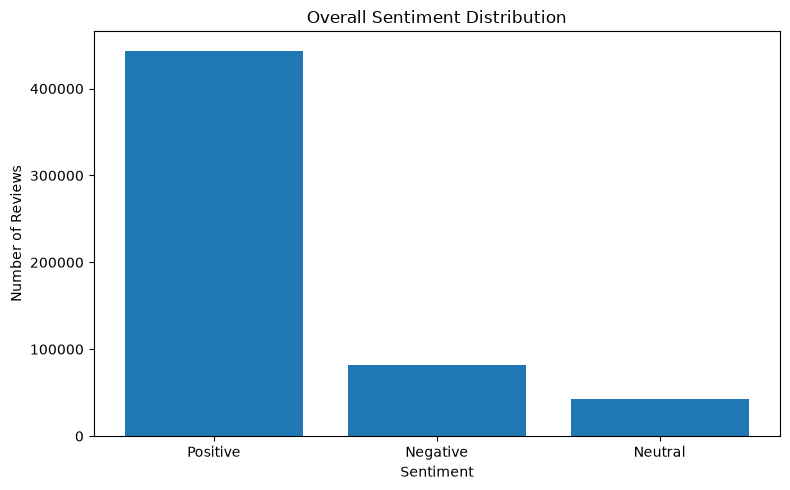

In [33]:
sentiment_counts = df["Sentiment"].value_counts()

plt.figure(figsize=(8, 5))
plt.bar(
    sentiment_counts.index,
    sentiment_counts.values
)

plt.title("Overall Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

In [34]:
sentiment_percentage = (
    df["Sentiment"].value_counts(normalize=True) * 100
).round(2)

print("Sentiment Percentage:")
print(sentiment_percentage)

Sentiment Percentage:
Sentiment
Positive    78.07
Negative    14.43
Neutral      7.50
Name: proportion, dtype: float64


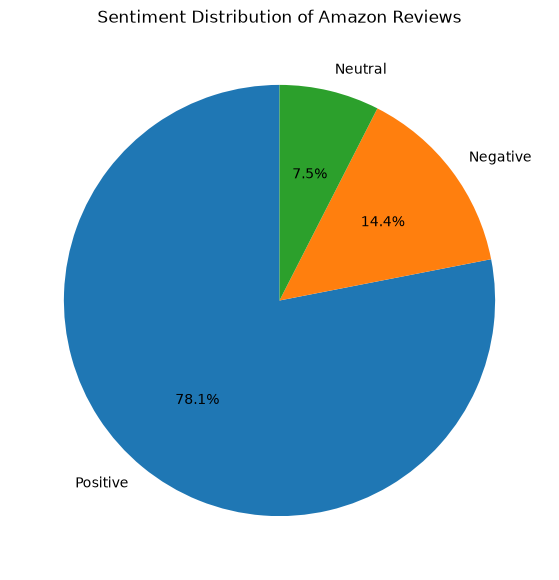

In [35]:
plt.figure(figsize=(7, 7))

plt.pie(
    sentiment_counts.values,
    labels=sentiment_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Sentiment Distribution of Amazon Reviews")
plt.show()

### Observation — Overall Sentiment Distribution

The sentiment distribution provides an overview of customer opinions across
the Amazon product reviews. The percentage of Positive, Negative, and Neutral
reviews helps identify the overall customer sentiment toward the products.
The actual percentages obtained from the dataset should be used when
interpreting the results.

In [36]:
product_sentiment = pd.crosstab(
    df["ProductId"],
    df["Sentiment"]
)

print(product_sentiment.head(10))

Sentiment   Negative  Neutral  Positive
ProductId                              
0006641040         2        3        32
141278509X         0        0         1
2734888454         1        0         1
2841233731         0        0         1
7310172001         4        6       163
7310172101         4        6       163
7800648702         0        1         1
9376674501         0        0         1
B00002N8SM        29        3         6
B00002NCJC         0        0         2


In [37]:
top_products = df["ProductId"].value_counts().head(10)

print("Top 10 products by number of reviews:")
print(top_products)

Top 10 products by number of reviews:
ProductId
B007JFMH8M    913
B002QWP89S    632
B0026RQTGE    632
B002QWHJOU    632
B002QWP8H0    632
B003B3OOPA    623
B001EO5Q64    567
B0013NUGDE    564
B007M83302    564
B000VK8AVK    564
Name: count, dtype: int64


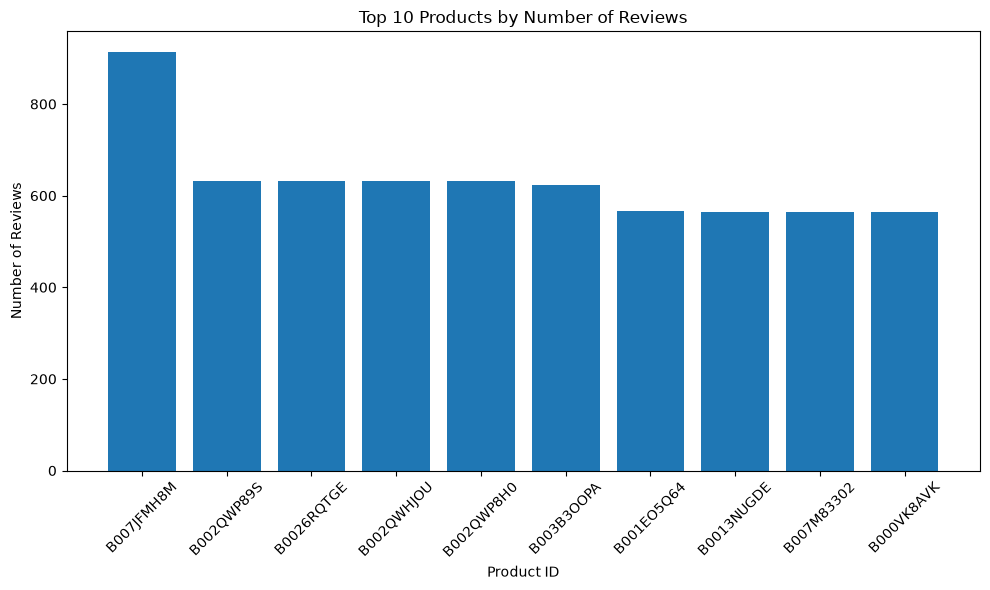

In [38]:
plt.figure(figsize=(10, 6))

plt.bar(
    top_products.index.astype(str),
    top_products.values
)

plt.title("Top 10 Products by Number of Reviews")
plt.xlabel("Product ID")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [39]:
product_rating = (
    df.groupby("ProductId")["Score"]
    .mean()
    .sort_values(ascending=False)
)

print("Top 10 products by average rating:")
print(product_rating.head(10))

Top 10 products by average rating:
ProductId
B009WVB40S    5.0
B009WSNWC4    5.0
141278509X    5.0
B009UUS05I    5.0
2841233731    5.0
B009SR4OQ2    5.0
B009SF0TN6    5.0
B009RSR8HO    5.0
9376674501    5.0
B009LIK0FW    5.0
Name: Score, dtype: float64


### Observation — Product-Level Sentiment Analysis

Customer reviews were analyzed at the product level using Product ID. The
number of reviews and average customer rating were examined to identify
products receiving greater customer attention and products with stronger
average ratings. This analysis can help identify products with positive
customer reception as well as products that may require further investigation.

In [40]:
df["Review_Length"] = df["Cleaned_Text"].str.len()

print("Review length statistics:")
print(df["Review_Length"].describe())

Review length statistics:
count    568454.000000
mean        412.719991
std         414.674092
min          12.000000
25%         171.000000
50%         288.000000
75%         501.000000
max       20379.000000
Name: Review_Length, dtype: float64


In [41]:
review_length_by_sentiment = (
    df.groupby("Sentiment")["Review_Length"]
    .mean()
    .round(2)
)

print("Average review length by sentiment:")
print(review_length_by_sentiment)

Average review length by sentiment:
Sentiment
Negative    456.91
Neutral     491.06
Positive    397.02
Name: Review_Length, dtype: float64


<Figure size 800x500 with 0 Axes>

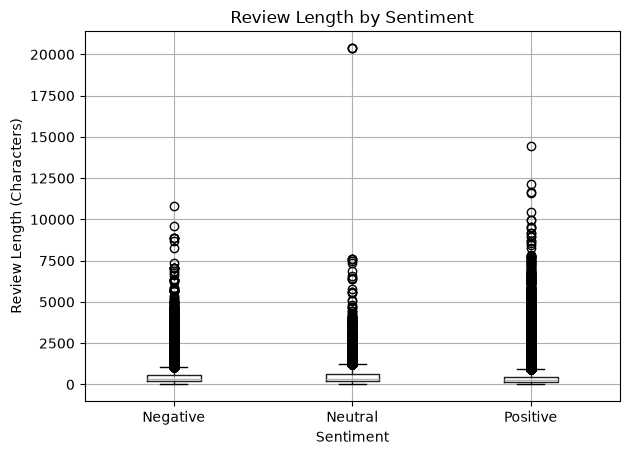

In [42]:
plt.figure(figsize=(8, 5))

df.boxplot(
    column="Review_Length",
    by="Sentiment"
)

plt.title("Review Length by Sentiment")
plt.suptitle("")
plt.xlabel("Sentiment")
plt.ylabel("Review Length (Characters)")
plt.tight_layout()
plt.show()

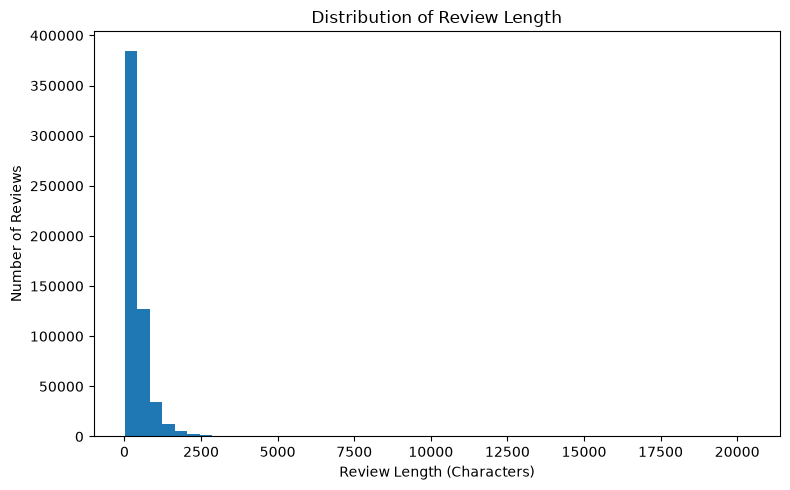

In [43]:
plt.figure(figsize=(8, 5))

plt.hist(
    df["Review_Length"],
    bins=50
)

plt.title("Distribution of Review Length")
plt.xlabel("Review Length (Characters)")
plt.ylabel("Number of Reviews")

plt.tight_layout()
plt.show()

### Observation — Review Length Analysis

Review length was calculated to understand the amount of text customers
provide in their reviews. The average review length was also compared across
sentiment categories. This analysis helps identify whether customers with
different sentiment levels tend to provide shorter or more detailed reviews.

In [44]:
print("========== FINAL SENTIMENT RESULTS ==========")

print("\nSentiment Distribution:")
print(df["Sentiment"].value_counts())

print("\nSentiment Percentage:")
print(
    (df["Sentiment"].value_counts(normalize=True) * 100).round(2)
)

print("\nAverage Review Length by Sentiment:")
print(
    df.groupby("Sentiment")["Review_Length"]
    .mean()
    .round(2)
)

print("\nAverage Product Rating:")
print(round(df["Score"].mean(), 2))

========== FINAL SENTIMENT RESULTS ==========

Sentiment Distribution:
Sentiment
Positive    443777
Negative     82037
Neutral      42640
Name: count, dtype: int64

Sentiment Percentage:
Sentiment
Positive    78.07
Negative    14.43
Neutral      7.50
Name: proportion, dtype: float64

Average Review Length by Sentiment:
Sentiment
Negative    456.91
Neutral     491.06
Positive    397.02
Name: Review_Length, dtype: float64

Average Product Rating:
4.18


## Business Insights

1. Customer sentiment can be classified into Positive, Neutral, and Negative
   categories using product review scores.

2. The sentiment distribution provides an overall view of customer
   satisfaction and dissatisfaction.

3. Frequently occurring words in positive reviews can highlight product
   features and qualities that customers appreciate.

4. Frequently occurring words in negative reviews can reveal common customer
   complaints and potential areas for improvement.

5. Product-level analysis can help identify products with high customer
   engagement and strong or weak average ratings.

6. Review-length analysis provides additional insight into how customers
   express their opinions across different sentiment categories.

## Business Recommendations

1. Monitor negative customer reviews regularly to identify recurring product
   or service problems.

2. Use frequently occurring positive review terms to understand product
   features that customers value and strengthen those features.

3. Investigate products with consistently low average ratings and high
   numbers of negative reviews.

4. Use automated sentiment classification to monitor large volumes of customer
   feedback more efficiently.

5. Combine sentiment results with product-level and rating-level analysis to
   support data-driven product improvement decisions.

## Conclusion

The Amazon Product Reviews dataset was analyzed using data cleaning,
sentiment classification, text analysis, and machine learning techniques.
Customer ratings were converted into Positive, Neutral, and Negative
sentiment categories. Review text was cleaned and analyzed using word
frequency techniques, while TF-IDF was used to convert text into numerical
features for Logistic Regression classification.

The analysis provides useful insights into customer opinions, commonly
discussed topics, product-level ratings, and review behavior. The results can
help businesses identify customer satisfaction patterns, detect common
complaints, and make data-driven decisions for improving products and
customer experience.

In [45]:
output_file = "../output/amazon_reviews_sentiment_analysis.csv"

df.to_csv(output_file, index=False)

print("Sentiment analysis results saved successfully!")
print("File:", output_file)

Sentiment analysis results saved successfully!
File: ../output/amazon_reviews_sentiment_analysis.csv


In [46]:
import os

print("Output file exists:", os.path.exists(output_file))

Output file exists: True
